In [1]:
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / 'dashboard/app.py').is_file():
    ROOT = ROOT.parent
DATA_DIR = ROOT / 'data'
HW_DATA_DIR = ROOT / 'HW/data'

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#Подготовка таблицы

In [2]:
df_pedagog1 = pd.read_excel('./data/Педагоги.xlsx', sheet_name='2022')
df_pedagog1['year']=2022

df_pedagog2 = pd.read_excel('./data/Педагоги.xlsx', sheet_name='2023')
df_pedagog2['year']=2023

df_pedagog3 = pd.read_excel('./data/Педагоги.xlsx', sheet_name='2024')
df_pedagog3['year']=2024

df_pedagog_all = pd.concat([df_pedagog1, df_pedagog2, df_pedagog3], axis=0)

In [3]:
df_pedagog_all = df_pedagog_all.rename(columns={'ID образовательной организации':'school_num',
                                                'Основная должность':'main_position',
                                                'Направление деятельности':'speciality',
                                                'Пол': 'sex',
                                                'Возраст':'age',
                                                'Ученая степень':'academic_degree',
                                                'Квалификационная категория (педагогического работника)':'category_qual',
                                                'Дата присвоения квалификационной категории':'category_date',
                                                'Срок действия квалификационной категории':'category_due',
                                                'Общий стаж работы':'experience_age_all',
                                                'Стаж педагогической работы':'experience_age_pedagogic',
                                                'Предмет':'subject',
                                                'Параллель':'parallel',
                                                'Имеет классное руководство':'class_manager'})

In [4]:
keywords = ['педагог', 'учитель', 'методист', 'преподават', 'воспитатель', 'тьютор']
matching_pedagog = set([item for item in df_pedagog_all.main_position.values
            if any(sub in str(item).lower() for sub in keywords)])
matching_pedagog = set([item for item in matching_pedagog if 'заместитель' not in str(item).lower()])

In [5]:
keywords_manager = ['заместитель', 'ведущий', 'заведующий', 'руководитель', 'начальник', 'главный']
matching_manager = set([item for item in df_pedagog_all.main_position.values
            if any(sub in str(item).lower() for sub in keywords_manager)])

In [6]:
matching_other = set(df_pedagog_all.main_position.unique()).difference(matching_pedagog.union(matching_manager))

In [7]:
matching_dict = {}

for val in matching_pedagog:
    matching_dict[val] = 'учитель'
for val in matching_manager:
    matching_dict[val] = 'руководитель'
for val in matching_other:
    matching_dict[val] = 'другой'

In [8]:
df_pedagog_all['main_position_cat'] = df_pedagog_all['main_position'].map(matching_dict).fillna('не_найдено')

In [9]:
df_pedagog_all['sex'] = df_pedagog_all['sex'].map({'Мужской': 1, 'Женский': 0})

In [10]:
keywords = {'кандидат': 'кандидат', 'доктор': 'доктор'}

def find_academic_degree(text):
    if pd.isna(text):
        return 'не_найдено'

    text = str(text).lower()
    for word, code in keywords.items():
        if word in text:
            return code
    return 'не_найдено'

df_pedagog_all['academic_degree_cat'] = df_pedagog_all['academic_degree'].apply(find_academic_degree)

In [11]:
keywords = {'высшая': 'высшая', 'первая': 'первая', 'вторая': 'вторая'}

def find_category_qual(text):
    if pd.isna(text):
        return 'не_найдено'

    text = str(text).lower()
    for word, code in keywords.items():
        if word in text:
            return code
    return 'не_найдено'

# Применяем функцию
df_pedagog_all['category_qual_cat'] = df_pedagog_all['category_qual'].apply(find_category_qual)

In [12]:
df_pedagog_all['category_date'] = df_pedagog_all['category_date'].astype('Int64')
df_pedagog_all['category_due'] = df_pedagog_all['category_due'].astype('Int64')

In [13]:
df_pedagog_all['category_active'] = df_pedagog_all.apply(lambda row: "не было" if pd.isna(row['category_due']) # Если нет данных
                                    else ("активно" if pd.to_datetime(row['category_due']) > pd.to_datetime(row['year']) # Если текущий год меньше года действия
                                    else "не активно"), axis=1)

In [14]:
df_pedagog_all['experience_age_other'] = df_pedagog_all.experience_age_all - df_pedagog_all.experience_age_pedagogic

In [15]:
df_pedagog_all['n_unique_subjects'] = (
    df_pedagog_all.groupby(['year', 'id'])['subject'].transform('nunique')
)

In [16]:
df_pedagog_all['min_parallel'] = (
    df_pedagog_all.groupby(['year', 'id'])['parallel'].transform('min')
)

In [17]:
df_pedagog_all['max_parallel'] = (
    df_pedagog_all.groupby(['year', 'id'])['parallel'].transform('max')
)

In [18]:
df_pedagog_all['n_unique_parallel'] = (
    df_pedagog_all.groupby(['year', 'id'])['parallel'].transform('nunique')
)

In [19]:
df_pedagog_all['class_manager'] = df_pedagog_all['class_manager'].map({'Да': 1, 'Нет': 0})

In [20]:
df_pedagog_all = df_pedagog_all.sort_values(['id', 'year'])
df_pedagog_all['max_year'] = df_pedagog_all.groupby('id')['year'].transform('max')
df_pedagog_all['is_out_next_year'] = (df_pedagog_all['year'] == df_pedagog_all['max_year']).astype(int)
df_pedagog_all = df_pedagog_all.drop(columns=['max_year'])

In [21]:
RULES = {
    'учитель': [
        'английского языка', 'русского языка', 'французского языка',
        'немецкого языка', 'испанского языка', 'итальянского языка',
        'китайского языка', 'арабского языка', 'родного языка',
        'родной литературы', 'литературы', 'литературного чтения',
        'истории', 'всеобщей истории', 'истории России',
        'обществознания', 'обществознания и естествознания (окружающий мир)',
        'права', 'экономики',
        'основ духовно-нравственной культуры народов России',
        'математики', 'алгебры', 'геометрии', 'физики', 'информатики',
        'математики и информатики', 'в сфере ИКТ', 'естествознания',
        'биологии', 'химии', 'географии',
        'изобразительного искусства', 'музыки', 'технологии',
        'физической культуры', 'основ безопасности жизнедеятельности',
        'начальных классов',
    ],

    'воспитатель': [
        'офицер кадетского класса', 'офицер-воспитатель кадетского класса',
        'по социальной работе',
        'по социализации, воспитанию и безопасности обучающихся',
        'по профориентации',
        'группы полного дня, группы ОВЗ', 'группы полного дня',
        'группы продленного дня', 'группы кратковременного пребывания',
        'группы ОВЗ', 'интерната, группы ОВЗ',
    ],

    'управление': [
        'по контролю качества образования', 'учебной части',
        'по содержанию образования, конвергенции образовательных программ',
        'по комплексной безопасности',
        'по материально-техническому обеспечению',
        'по управлению ресурсами', 'по питанию',
        'по финансово-экономической деятельности', 'по учету контингента',
        'по музейной работе', 'учебно-производственной мастерской',
    ],
}

In [22]:
value_to_group = {}
for group, values in RULES.items():
    for v in values:
        value_to_group[v.strip().lower()] = group


def categorize(value):
    if pd.isna(value):
        return 'не указано'
    v = str(value).strip().lower()
    return value_to_group.get(v, 'прочее')

In [23]:
df_pedagog_all['speciality_cat'] = df_pedagog_all['speciality'].apply(categorize)

In [24]:
df_pedagog_clean = df_pedagog_all.drop_duplicates(subset=['id', 'year'], keep='first')

In [25]:
del df_pedagog_clean['academic_degree']
del df_pedagog_clean['main_position']
del df_pedagog_clean['speciality']
del df_pedagog_clean['category_qual']
del df_pedagog_clean['subject']
del df_pedagog_clean['parallel']

In [26]:
del df_pedagog_clean['age']
del df_pedagog_clean['experience_age_all']
del df_pedagog_clean['category_due']

df_pedagog_clean = df_pedagog_clean[df_pedagog_clean['year'] != 2024]

In [27]:
from scipy.stats.mstats import winsorize

df_pedagog_clean['experience_age_pedagogic'] = np.array(
    winsorize(df_pedagog_clean['experience_age_pedagogic'].values, limits=[0.01, 0.01])
)

In [28]:
df_pedagog_clean['n_unique_subjects'] = np.log1p(df_pedagog_clean['n_unique_subjects'])

In [29]:
df_pedagog_clean.loc[df_pedagog_clean['experience_age_other'] < 0, 'experience_age_other'] = 0

In [30]:
df_pedagog_clean['category_date'] = df_pedagog_clean['category_date'].fillna(1900)

мы подготовили учителей для двух разных моелей. Которые могут работать с категориальными данными и нет

In [31]:
df_pedagog_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 35632 entries, 95509 to 61723
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        35632 non-null  object 
 1   school_num                35632 non-null  int64  
 2   sex                       35632 non-null  int64  
 3   category_date             35632 non-null  Int64  
 4   experience_age_pedagogic  35632 non-null  int64  
 5   class_manager             35632 non-null  int64  
 6   year                      35632 non-null  int64  
 7   main_position_cat         35632 non-null  object 
 8   academic_degree_cat       35632 non-null  object 
 9   category_qual_cat         35632 non-null  object 
 10  category_active           35632 non-null  object 
 11  experience_age_other      35632 non-null  int64  
 12  n_unique_subjects         35632 non-null  float64
 13  min_parallel              35632 non-null  int64  
 14  max_par

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler,
    RobustScaler, FunctionTransformer, TargetEncoder,
)

#Подготовка данных

In [34]:
def _academic_degree_bin(X):
    mapping = {"не_найдено": 0, "кандидат": 1, "доктор": 1}
    out = X["academic_degree_cat"].map(mapping).fillna(0).astype(int)
    return out.to_frame("academic_degree_bin")

def _category_qual_grouped(X):
    mapping = {"не_найдено": 0, "первая": 1, "вторая": 1, "высшая": 2}
    out = X["category_qual_cat"].map(mapping).fillna(0).astype(int)
    return out.to_frame("category_qual_grouped")

academic_degree_step = FunctionTransformer(
    _academic_degree_bin, validate=False,
    feature_names_out=lambda self, input_features: np.array(["academic_degree_bin"]),
)

category_qual_grouped_step = FunctionTransformer(
    _category_qual_grouped, validate=False,
    feature_names_out=lambda self, input_features: np.array(["category_qual_grouped"]),
)

Вариант данных для моделей, требующие масштабирование и кодирование

In [35]:
preprocess_scaled = ColumnTransformer([
    # target encoding
    ('te', TargetEncoder(target_type='binary', smooth='auto', cv=5, random_state=42),
     ['school_num']),

    # standard
    ('std', StandardScaler(),
     ['n_unique_subjects', 'n_unique_parallel', 'experience_age_pedagogic']),

    # minmax
    ('minmax', MinMaxScaler(), ['min_parallel', 'max_parallel']),

    # robust
    ('robust', RobustScaler(), ['experience_age_other']),

    # бинарные как есть
    ('bin', 'passthrough', ['sex', 'class_manager']),

    # бинарка
    ('academic', academic_degree_step, ['academic_degree_cat']),

    # map + standard
    ('qual', Pipeline([
        ('map', category_qual_grouped_step),
        ('scaler', StandardScaler()),
    ]), ['category_qual_cat']),

    # ordinal + minmax
    ('active', Pipeline([
        ('ord', OrdinalEncoder(
            categories=[['не было', 'не активно', 'активно']],
            handle_unknown='use_encoded_value', unknown_value=-1,
        )),
        ('scaler', MinMaxScaler()),
    ]), ['category_active']),

    # OHE
    ('ohe_position', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['main_position_cat']),
    ('ohe_speciality', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['speciality_cat']),
], remainder='drop', verbose_feature_names_out=False)

где требуется только кодирование

In [36]:
preprocess_tree = ColumnTransformer([
    ('te', TargetEncoder(target_type='binary', smooth='auto', cv=5, random_state=42),
     ['school_num']),

    ('num', 'passthrough',
     ['sex', 'class_manager', 'experience_age_pedagogic', 'experience_age_other',
      'n_unique_subjects', 'min_parallel', 'max_parallel', 'n_unique_parallel']),

    ('academic', academic_degree_step, ['academic_degree_cat']),

    ('qual', category_qual_grouped_step, ['category_qual_cat']),

    ('active', OrdinalEncoder(
        categories=[['не было', 'не активно', 'активно']],
        handle_unknown='use_encoded_value', unknown_value=-1,
    ), ['category_active']),

    ('ohe_position', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['main_position_cat']),
    ('ohe_speciality', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['speciality_cat']),
], remainder='drop', verbose_feature_names_out=False)

Чистый вариант

In [37]:
preprocess_xgb = ColumnTransformer([
    ('cat', 'passthrough',
     ['school_num', 'main_position_cat', 'speciality_cat',
      'academic_degree_cat', 'category_qual_cat', 'category_active']),
    ('num', 'passthrough',
     ['sex', 'class_manager', 'experience_age_pedagogic', 'experience_age_other',
      'n_unique_subjects', 'min_parallel', 'max_parallel', 'n_unique_parallel']),
], remainder='drop', verbose_feature_names_out=False)

Разбиение на обучение и тест

In [38]:
FEATURES = [
    'school_num', 'sex', 'experience_age_pedagogic', 'class_manager',
    'main_position_cat', 'academic_degree_cat', 'category_qual_cat',
    'category_active', 'experience_age_other', 'n_unique_subjects',
    'min_parallel', 'max_parallel', 'n_unique_parallel', 'speciality_cat',
]
# исключили 'category_date', 'id', 'year', 'is_out_next_year'

train = df_pedagog_clean[df_pedagog_clean['year'] == 2022]
test  = df_pedagog_clean[df_pedagog_clean['year'] == 2023]

X_train, y_train = train[FEATURES], train['is_out_next_year']
X_test,  y_test  = test[FEATURES],  test['is_out_next_year']

# Простые алгоритмы

K-Nearest Neighbors (метод k ближайших соседей)

In [40]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score

knn = Pipeline([
    ('prep', preprocess_scaled),
    ('clf', KNeighborsClassifier(n_neighbors=5)),
])

knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print("accuracy:         ", accuracy_score(y_test, y_pred))
print("balanced_accuracy:", balanced_accuracy_score(y_test, y_pred))

accuracy:          0.8688690375863812
balanced_accuracy: 0.5164668107790923


k=3: accuracy=0.8554  balanced_accuracy=0.5228
k=5: accuracy=0.8689  balanced_accuracy=0.5165
k=7: accuracy=0.8739  balanced_accuracy=0.5100
k=9: accuracy=0.8762  balanced_accuracy=0.5059
k=11: accuracy=0.8782  balanced_accuracy=0.5031


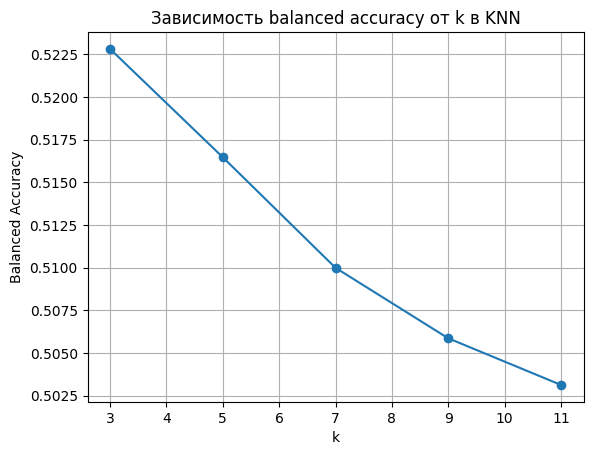

In [ ]:
k_values = [3, 5, 7, 9, 11]
results = []

for k in k_values:
    knn = Pipeline([
        ('prep', preprocess_scaled),
        ('clf', KNeighborsClassifier(n_neighbors=k)),
    ])
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)

    acc  = accuracy_score(y_test, y_pred)
    bacc = balanced_accuracy_score(y_test, y_pred)

    results.append({'k': k, 'accuracy': acc, 'balanced_accuracy': bacc})
    print(f"k={k}: accuracy={acc:.4f}  balanced_accuracy={bacc:.4f}")

# Визуализация по balanced accuracy
plt.plot(k_values, [r['balanced_accuracy'] for r in results], marker='o')
plt.xlabel('k')
plt.ylabel('Balanced Accuracy')
plt.title('Зависимость balanced accuracy от k в KNN')
plt.grid(True)
plt.show()

Decision Tree (дерево решений)

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = Pipeline([
    ('prep', preprocess_tree),
    ('clf', DecisionTreeClassifier(max_depth=3, random_state=42)),
])

dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print("accuracy:         ", accuracy_score(y_test, y_pred_dt))
print("balanced_accuracy:", balanced_accuracy_score(y_test, y_pred_dt))

accuracy:          0.880442721501208
balanced_accuracy: 0.5013745535091447


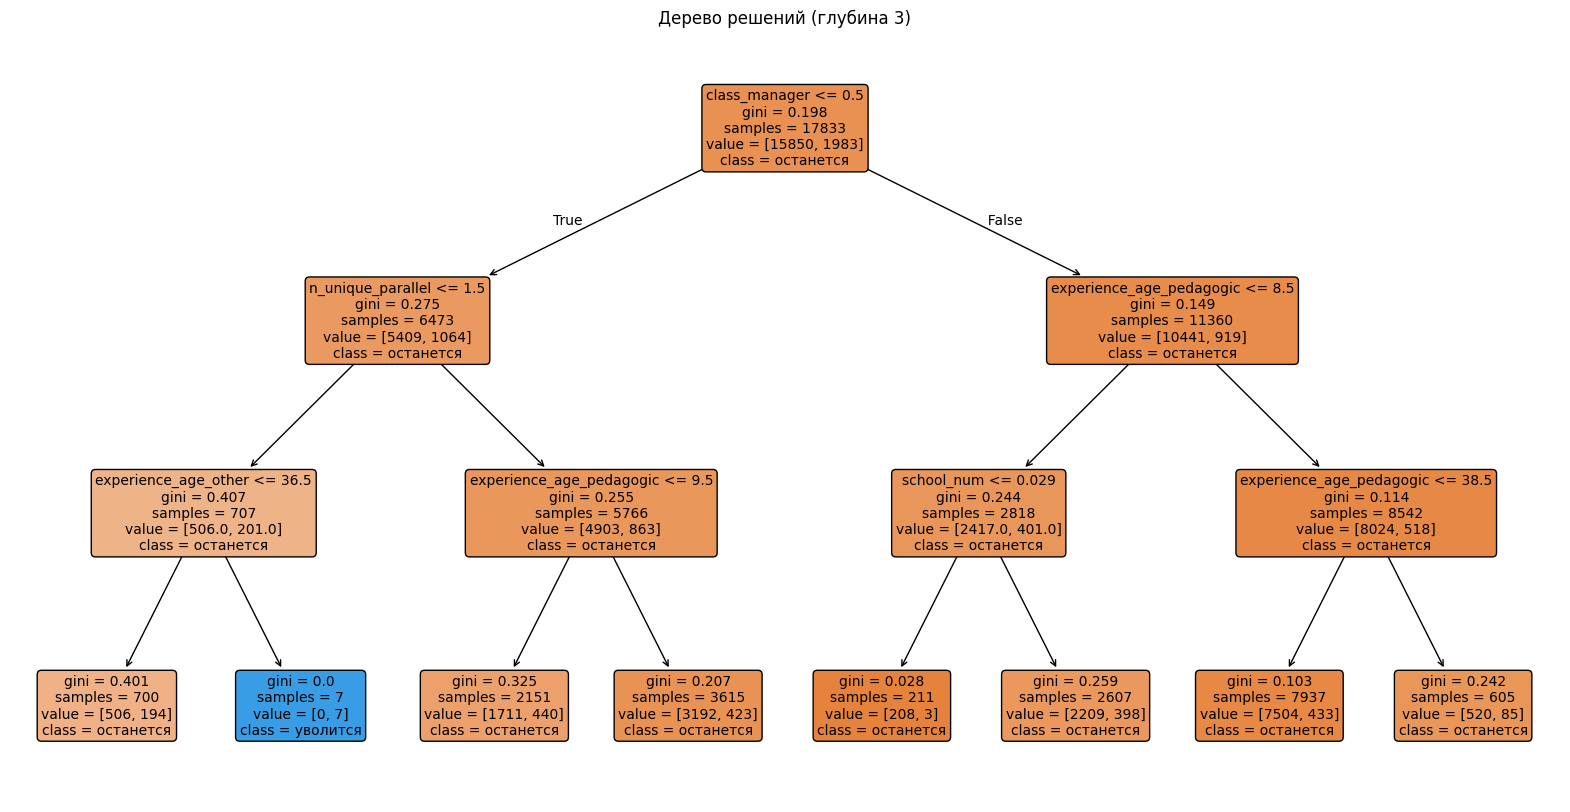

In [ ]:
tree_model    = dt.named_steps['clf']
feature_names = dt.named_steps['prep'].get_feature_names_out()

plt.figure(figsize=(20, 10))
plot_tree(
    tree_model,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    class_names=['останется', 'уволится'],
    fontsize=10,
)
plt.title('Дерево решений (глубина 3)')
plt.show()

In [ ]:
prep       = dt.named_steps['prep']
tree_model = dt.named_steps['clf']

feature_names = prep.get_feature_names_out()

feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': tree_model.feature_importances_,
}).sort_values('importance', ascending=False)

print("Топ-5 важных признаков по версии дерева:")
print(feature_importance.head(5))

Топ-5 важных признаков по версии дерева:
                    feature  importance
2             class_manager    0.377441
3  experience_age_pedagogic    0.375899
8         n_unique_parallel    0.149942
0                school_num    0.049148
4      experience_age_other    0.047570


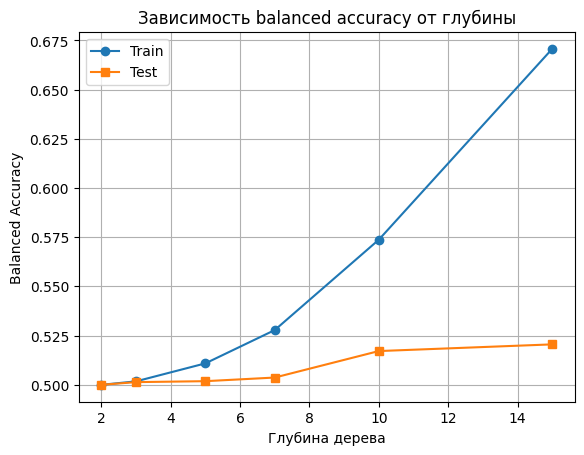

In [ ]:
depths = [2, 3, 5, 7, 10, 15]
train_scores = []
test_scores  = []
train_bacc   = []
test_bacc    = []

for depth in depths:
    dt_temp = Pipeline([
        ('prep', preprocess_tree),
        ('clf', DecisionTreeClassifier(max_depth=depth, random_state=42)),
    ])
    dt_temp.fit(X_train, y_train)

    y_tr = dt_temp.predict(X_train)
    y_te = dt_temp.predict(X_test)

    train_scores.append(accuracy_score(y_train, y_tr))
    test_scores.append(accuracy_score(y_test, y_te))
    train_bacc.append(balanced_accuracy_score(y_train, y_tr))
    test_bacc.append(balanced_accuracy_score(y_test, y_te))

# График
plt.plot(depths, train_bacc, marker='o', label='Train')
plt.plot(depths, test_bacc, marker='s', label='Test')
plt.xlabel('Глубина дерева')
plt.ylabel('Balanced Accuracy')
plt.title('Зависимость balanced accuracy от глубины')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
dt_deep = Pipeline([
    ('prep', preprocess_tree),
    ('clf', DecisionTreeClassifier(max_depth=None, random_state=42)),
])

dt_deep.fit(X_train, y_train)

y_tr = dt_deep.predict(X_train)
y_te = dt_deep.predict(X_test)

train_acc  = accuracy_score(y_train, y_tr)
test_acc   = accuracy_score(y_test, y_te)
train_bacc = balanced_accuracy_score(y_train, y_tr)
test_bacc  = balanced_accuracy_score(y_test, y_te)

print("Глубокое дерево (без ограничений):")
print(f"accuracy          train={train_acc:.4f}  test={test_acc:.4f}  gap={train_acc - test_acc:.4f} — переобучение")
print(f"balanced_accuracy train={train_bacc:.4f}  test={test_bacc:.4f}  gap={train_bacc - test_bacc:.4f} — переобучение")

Глубокое дерево (без ограничений):
accuracy          train=0.9124  test=0.7692  gap=0.1432 — переобучение
balanced_accuracy train=0.7833  test=0.5299  gap=0.2533 — переобучение


Logistic Regression (логистическая регрессия)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = Pipeline([
    ('prep', preprocess_scaled),
    ('clf', LogisticRegression(random_state=42, max_iter=1000)),
])

lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("accuracy:         ", accuracy_score(y_test, y_pred_lr))
print("balanced_accuracy:", balanced_accuracy_score(y_test, y_pred_lr))

accuracy:          0.880442721501208
balanced_accuracy: 0.5031970118846965


с балансировкой

In [ ]:
lr_balanced = Pipeline([
    ('prep', preprocess_scaled),
    ('clf', LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)),
])

lr_balanced.fit(X_train, y_train)
y_pred_balanced = lr_balanced.predict(X_test)

print(f"Accuracy:          {accuracy_score(y_test, y_pred_balanced):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_balanced):.4f}")

Accuracy:          0.6626
Balanced accuracy: 0.6358


In [ ]:
prep = lr_balanced.named_steps['prep']
clf  = lr_balanced.named_steps['clf']

feature_names = prep.get_feature_names_out()

coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': clf.coef_[0],
}).sort_values('coefficient', ascending=False)

print("Топ-5 признаков, увеличивающих вероятность увольнения:")
print(coef_df.head(5))

print("\nТоп-5 признаков, снижающих вероятность увольнения:")
print(coef_df.tail(5))

Топ-5 признаков, увеличивающих вероятность увольнения:
                           feature  coefficient
0                       school_num     3.971566
4                     min_parallel     0.438518
12        main_position_cat_другой     0.293214
13  main_position_cat_руководитель     0.173256
16       speciality_cat_не указано     0.127292

Топ-5 признаков, снижающих вероятность увольнения:
                       feature  coefficient
9          academic_degree_bin    -0.201762
10       category_qual_grouped    -0.219092
15  speciality_cat_воспитатель    -0.219512
14   main_position_cat_учитель    -0.449942
8                class_manager    -0.627338


In [ ]:
y_proba = lr_balanced.predict_proba(X_test)[:, 1]

y_pred_std = (y_proba >= 0.5).astype(int)
y_pred_low = (y_proba >= 0.3).astype(int)

for name, yp in [("0.5", y_pred_std), ("0.3", y_pred_low)]:
    print(f"Порог {name}:")
    print(f"  accuracy:          {accuracy_score(y_test, yp):.4f}")
    print(f"  balanced_accuracy: {balanced_accuracy_score(y_test, yp):.4f}")
    print(f"  найдено увольнений: {yp.sum()}")
    print()

print(f"Всего в тесте (y_test==1): {(y_test == 1).sum()}")

Порог 0.5:
  accuracy:          0.6626
  balanced_accuracy: 0.6358
  найдено увольнений: 6434

Порог 0.3:
  accuracy:          0.2156
  balanced_accuracy: 0.5366
  найдено увольнений: 15918

Всего в тесте (y_test==1): 2133


Support Vector Machine (метод опорных векторов)

In [ ]:
from sklearn.svm import SVC
import time

print("SVM может учиться долго на больших данных...")

start = time.time()

svm = Pipeline([
    ('prep', preprocess_scaled),
    ('clf', SVC(kernel='linear', random_state=42)),
])

svm.fit(X_train, y_train)

end = time.time()
print(f"Время обучения: {end - start:.2f} сек")

y_pred_svm = svm.predict(X_test)
print(f"Accuracy SVM (linear):          {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Balanced accuracy SVM (linear): {balanced_accuracy_score(y_test, y_pred_svm):.4f}")

SVM может учиться долго на больших данных...
Время обучения: 2.37 сек
Accuracy SVM (linear):          0.8802
Balanced accuracy SVM (linear): 0.5000


In [ ]:
print("Распределение предсказаний SVM:")
print(pd.Series(y_pred_svm).value_counts())

# Сравним с реальным распределением
print("\nРеальное распределение в тесте:")
print(y_test.value_counts())

Распределение предсказаний SVM:
0    17799
Name: count, dtype: int64

Реальное распределение в тесте:
is_out_next_year
0    15666
1     2133
Name: count, dtype: int64


Добавим балансировку SMOTE и посмотрим точность на разных ядрах

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

kernels = ['linear', 'rbf']
for kernel in kernels:
    pipe_svm = ImbPipeline([
        ('prep', preprocess_scaled),
        ('smote', SMOTE(random_state=42)),
        ('clf', SVC(kernel=kernel, random_state=42)),
    ])
    pipe_svm.fit(X_train, y_train)
    y_pred = pipe_svm.predict(X_test)

    print(f"Ядро {kernel}: "
          f"accuracy={accuracy_score(y_test, y_pred):.4f}  "
          f"balanced_accuracy={balanced_accuracy_score(y_test, y_pred):.4f}")

Ядро linear: accuracy=0.6498  balanced_accuracy=0.5896
Ядро rbf: accuracy=0.7565  balanced_accuracy=0.6343


#Ансамблевые методы

Бэггинг (Bagging — Bootstrap Aggregating)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

start = time.time()

rf = Pipeline([
    ('prep', preprocess_tree),
    ('clf', RandomForestClassifier(
        n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)),
])

rf.fit(X_train, y_train)

end = time.time()
print(f"Время обучения Random Forest: {end - start:.2f} сек")

y_pred_rf = rf.predict(X_test)

print(f"Accuracy:          {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_rf):.4f}")

print("\nРаспределение предсказаний:")
print(pd.Series(y_pred_rf).value_counts())

Время обучения Random Forest: 2.85 сек
Accuracy:          0.8797
Balanced accuracy: 0.5052

Распределение предсказаний:
0    17736
1       63
Name: count, dtype: int64


In [ ]:
prep = rf.named_steps['prep']
clf  = rf.named_steps['clf']

feature_names = prep.get_feature_names_out()

feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': clf.feature_importances_,
}).sort_values('importance', ascending=False)

print("Топ-10 важных признаков:")
print(feature_importance.head(10))

Топ-10 важных признаков:
                     feature  importance
0                 school_num    0.231368
3   experience_age_pedagogic    0.193459
4       experience_age_other    0.104724
5          n_unique_subjects    0.090473
6               min_parallel    0.083500
7               max_parallel    0.082327
8          n_unique_parallel    0.078447
2              class_manager    0.032266
10     category_qual_grouped    0.030901
11           category_active    0.028717


n_estimators=10: accuracy=0.8754  balanced_accuracy=0.5046
n_estimators=50: accuracy=0.8792  balanced_accuracy=0.5053
n_estimators=100: accuracy=0.8797  balanced_accuracy=0.5052
n_estimators=200: accuracy=0.8799  balanced_accuracy=0.5053


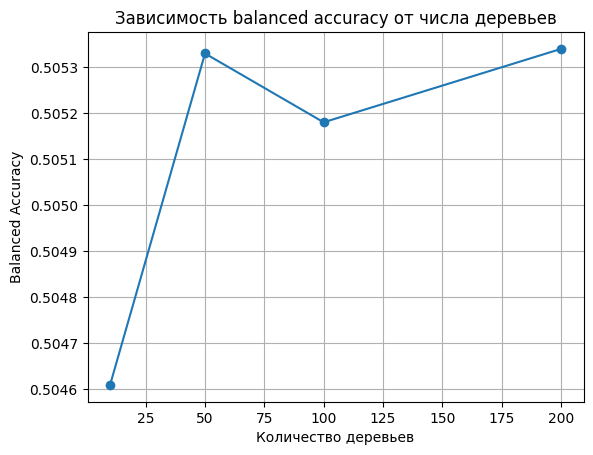

In [ ]:
n_estimators_list = [10, 50, 100, 200]
acc_scores  = []
bacc_scores = []

for n in n_estimators_list:
    rf_temp = Pipeline([
        ('prep', preprocess_tree),
        ('clf', RandomForestClassifier(
            n_estimators=n, random_state=42,
            class_weight='balanced', n_jobs=-1)),
    ])
    rf_temp.fit(X_train, y_train)
    y_pred = rf_temp.predict(X_test)

    acc_scores.append(accuracy_score(y_test, y_pred))
    bacc_scores.append(balanced_accuracy_score(y_test, y_pred))
    print(f"n_estimators={n}: accuracy={acc_scores[-1]:.4f}  "
          f"balanced_accuracy={bacc_scores[-1]:.4f}")

plt.plot(n_estimators_list, bacc_scores, marker='o')
plt.xlabel('Количество деревьев')
plt.ylabel('Balanced Accuracy')
plt.title('Зависимость balanced accuracy от числа деревьев')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# --- Обычный KNN (для сравнения) ---
knn_simple = Pipeline([
    ('prep', preprocess_scaled),
    ('clf', KNeighborsClassifier(n_neighbors=5)),
])
knn_simple.fit(X_train, y_train)
y_pred_knn = knn_simple.predict(X_test)

print(f"Обычный KNN (k=5):")
print(f"  accuracy:          {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"  balanced_accuracy: {balanced_accuracy_score(y_test, y_pred_knn):.4f}")
print(f"  найдено увольнений: {y_pred_knn.sum()}")

# --- KNN + SMOTE ---
knn_smote = ImbPipeline([
    ('prep', preprocess_scaled),
    ('smote', SMOTE(random_state=42)),
    ('clf', KNeighborsClassifier(n_neighbors=5)),
])
knn_smote.fit(X_train, y_train)
y_pred_knn_smote = knn_smote.predict(X_test)

print(f"\nKNN + SMOTE:")
print(f"  accuracy:          {accuracy_score(y_test, y_pred_knn_smote):.4f}")
print(f"  balanced_accuracy: {balanced_accuracy_score(y_test, y_pred_knn_smote):.4f}")
print(f"  найдено увольнений: {y_pred_knn_smote.sum()}")

# --- Бэггинг из 50 KNN ---
bagging_knn = Pipeline([
    ('prep', preprocess_scaled),
    ('clf', BaggingClassifier(
        estimator=KNeighborsClassifier(n_neighbors=5),
        n_estimators=50, random_state=42, n_jobs=-1)),
])
bagging_knn.fit(X_train, y_train)
y_pred_bagging_knn = bagging_knn.predict(X_test)

print(f"\nБэггинг над KNN (50 моделей):")
print(f"  accuracy:          {accuracy_score(y_test, y_pred_bagging_knn):.4f}")
print(f"  balanced_accuracy: {balanced_accuracy_score(y_test, y_pred_bagging_knn):.4f}")
print(f"  найдено увольнений: {y_pred_bagging_knn.sum()}")

# --- Бэггинг над KNN + SMOTE ---
bagging_knn_smote = ImbPipeline([
    ('prep', preprocess_scaled),
    ('smote', SMOTE(random_state=42)),
    ('clf', BaggingClassifier(
        estimator=KNeighborsClassifier(n_neighbors=5),
        n_estimators=50, random_state=42, n_jobs=-1)),
])
bagging_knn_smote.fit(X_train, y_train)
y_pred_bagging_knn_smote = bagging_knn_smote.predict(X_test)

print(f"\nБэггинг над KNN + SMOTE:")
print(f"  accuracy:          {accuracy_score(y_test, y_pred_bagging_knn_smote):.4f}")
print(f"  balanced_accuracy: {balanced_accuracy_score(y_test, y_pred_bagging_knn_smote):.4f}")
print(f"  найдено увольнений: {y_pred_bagging_knn_smote.sum()}")

Обычный KNN (k=5):
  accuracy:          0.8689
  balanced_accuracy: 0.5165
  найдено увольнений: 427

KNN + SMOTE:
  accuracy:          0.7132
  balanced_accuracy: 0.5718
  найдено увольнений: 4618

Бэггинг над KNN (50 моделей):
  accuracy:          0.8694
  balanced_accuracy: 0.5155
  найдено увольнений: 406

Бэггинг над KNN + SMOTE:
  accuracy:          0.7238
  balanced_accuracy: 0.5774
  найдено увольнений: 4425


Бустинг (Boosting)

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

ada = Pipeline([
    ('prep', preprocess_tree),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100,
        random_state=42)),
])

ada.fit(X_train, y_train)
y_pred_ada = ada.predict(X_test)

print(f"AdaBoost (100 пней):")
print(f"  accuracy:          {accuracy_score(y_test, y_pred_ada):.4f}")
print(f"  balanced_accuracy: {balanced_accuracy_score(y_test, y_pred_ada):.4f}")
print(f"  найдено увольнений: {y_pred_ada.sum()}")

AdaBoost (100 пней):
  accuracy:          0.8806
  balanced_accuracy: 0.5037
  найдено увольнений: 27


In [41]:
from xgboost import XGBClassifier

cat_cols = ['school_num', 'main_position_cat', 'speciality_cat',
            'academic_degree_cat', 'category_qual_cat', 'category_active']

X_train_xgb = X_train.copy()
X_test_xgb  = X_test.copy()

for c in cat_cols:
    X_train_xgb[c] = X_train_xgb[c].astype('category')
for c in cat_cols:
    cats = X_train_xgb[c].cat.categories
    X_test_xgb[c] = pd.Categorical(X_test_xgb[c], categories=cats)

xgb = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='logloss',
    enable_categorical=True,
    tree_method='hist',
)

xgb.fit(X_train_xgb, y_train)
y_pred_xgb = xgb.predict(X_test_xgb)

print(f"XGBoost (100 деревьев):")
print(f"  accuracy:          {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"  balanced_accuracy: {balanced_accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"  найдено увольнений: {y_pred_xgb.sum()}")

xgb_importance = pd.DataFrame({
    'feature': X_train_xgb.columns,
    'importance': xgb.feature_importances_,
}).sort_values('importance', ascending=False)
print("\nТоп-5 признаков по версии XGBoost:")
print(xgb_importance.head(5))

XGBoost (100 деревьев):
  accuracy:          0.8724
  balanced_accuracy: 0.5174
  найдено увольнений: 355

Топ-5 признаков по версии XGBoost:
                     feature  importance
3              class_manager    0.240982
0                 school_num    0.135425
4          main_position_cat    0.074074
2   experience_age_pedagogic    0.071613
12         n_unique_parallel    0.062707


In [42]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos_weight = neg / pos
print(f"Соотношение классов: {scale_pos_weight:.2f} (neg/pos)")

xgb_balanced = XGBClassifier(
    n_estimators=100,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
    enable_categorical=True,   # обязательно для category dtype
    tree_method='hist',        # обязательно для категорий
)

xgb_balanced.fit(X_train_xgb, y_train)
y_pred_xgb_balanced = xgb_balanced.predict(X_test_xgb)

print("\nXGBoost с scale_pos_weight:")
print(f"Accuracy:          {accuracy_score(y_test, y_pred_xgb_balanced):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_xgb_balanced):.4f}")
print(f"Найдено увольнений: {y_pred_xgb_balanced.sum()}")
print(pd.Series(y_pred_xgb_balanced).value_counts())

Соотношение классов: 7.99 (neg/pos)

XGBoost с scale_pos_weight:
Accuracy:          0.8315
Balanced accuracy: 0.5335
Найдено увольнений: 1470
0    16329
1     1470
Name: count, dtype: int64


Стэкинг (Stacking)

In [49]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import pandas as pd


base_models = [
    # KNN — вариант A + SMOTE
    ('knn', ImbPipeline([
        ('prep', preprocess_scaled),
        ('smote', SMOTE(random_state=42)),
        ('clf', KNeighborsClassifier(n_neighbors=5)),
    ])),

    # DT — вариант B
    ('tree', Pipeline([
        ('prep', preprocess_tree),
        ('clf', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)),
    ])),

    # RF — вариант B
    ('rf', Pipeline([
        ('prep', preprocess_tree),
        ('clf', RandomForestClassifier(
            n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)),
    ])),
]

meta_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

stacking = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=5, # 5-кратная кросс-валидация для предсказаний базовых моделей
    n_jobs=-1,
)

stacking.fit(X_train, y_train)
y_pred_stacking = stacking.predict(X_test)

print("Stacking:")
print(f"  accuracy:          {accuracy_score(y_test, y_pred_stacking):.4f}")
print(f"  balanced_accuracy: {balanced_accuracy_score(y_test, y_pred_stacking):.4f}")
print(f"  найдено увольнений: {y_pred_stacking.sum()}")
print(f"  реальных в тесте:   {(y_test == 1).sum()}")
print(pd.Series(y_pred_stacking).value_counts())

Stacking:
  accuracy:          0.6399
  balanced_accuracy: 0.6468
  найдено увольнений: 7075
  реальных в тесте:   2133
0    10724
1     7075
Name: count, dtype: int64


In [47]:
meta = stacking.final_estimator_
base_names = ['knn', 'tree', 'rf']

coef_df = pd.DataFrame({
    'base_model': base_names,
    'coefficient': meta.coef_[0],
}).sort_values('coefficient', ascending=False)

print("Коэффициенты мета-модели (веса базовых моделей):")
print(coef_df.to_string(index=False))
print(f"\nintercept: {meta.intercept_[0]:.4f}")

Коэффициенты мета-модели (веса базовых моделей):
base_model  coefficient
      tree     2.907666
        rf     2.387047
       knn     0.154140

intercept: -1.8029
